# Exercise 12: Support Vector Machine (Part 1) - Solution
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

## Task 1: Load the Wine dataset and build a 2-class, 2-feature subset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
feature_names = wine.feature_names
class_names = wine.target_names
print("Features:", feature_names[:4], "...")
print("Classes :", class_names)

# Keep classes 0 and 1, and only the features 'alcohol' and 'malic_acid'
mask = (y == 0) | (y == 1)
X2 = X.loc[mask, ['alcohol', 'malic_acid']].to_numpy()
y2 = y[mask].to_numpy()

print("Number of samples per class:")
print(pd.Series(y2).value_counts())

Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash'] ...
Classes : ['class_0' 'class_1' 'class_2']
Number of samples per class:
1    71
0    59
Name: count, dtype: int64


## Task 2: Scatter plot of the two classes (raw features).

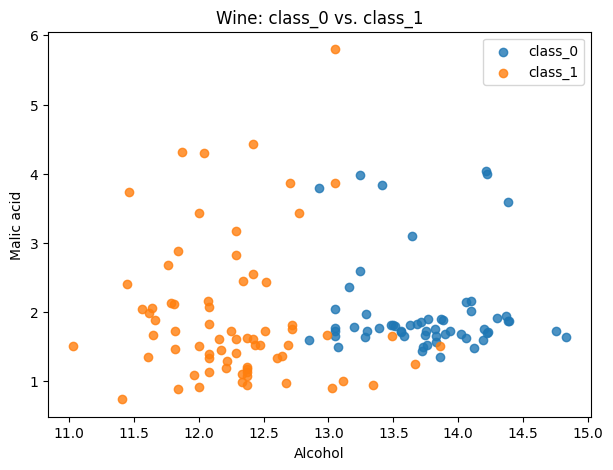

In [ ]:
plt.figure(figsize=(7, 5))
for cls, name, color in zip([0, 1], [class_names[0], class_names[1]], ['tab:blue', 'tab:orange']):
    pts = X2[y2 == cls]
    plt.scatter(pts[:, 0], pts[:, 1], label=name, alpha=0.8, c=color)
plt.xlabel("Alcohol")
plt.ylabel("Malic acid")
plt.title("Wine: class_0 vs. class_1")
plt.legend()
plt.show()

## Task 3: Train/test split and standardization.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X2, y2, test_size=0.3, random_state=2026, stratify=y2)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print("Train mean (std):", X_train_s.mean(axis=0).round(3))
print("Train std  (std):", X_train_s.std(axis=0).round(3))

Train mean (std): [0. 0.]
Train std  (std): [1. 1.]


## Task 4: Train SVMs with large and small C.

In [ ]:
svm_large_C = SVC(kernel='linear', C=100.0)
svm_small_C = SVC(kernel='linear', C=0.1)
svm_large_C.fit(X_train_s, y_train)
svm_small_C.fit(X_train_s, y_train)

def report(name, model):
    print(f"\n--- {name} ---")
    print(f"Train accuracy : {model.score(X_train_s, y_train):.4f}")
    print(f"Test  accuracy : {model.score(X_test_s,  y_test):.4f}")
    print(f"# Support vectors (per class): {model.n_support_}")
    print(f"||w||          : {np.linalg.norm(model.coef_):.4f}")

report("SVM with C = 100",  svm_large_C)
report("SVM with C = 0.1",  svm_small_C)


--- SVM with C = 100 ---
Train accuracy : 0.9121
Test  accuracy : 0.9744
# Support vectors (per class): [11 11]
||w||          : 1.9640

--- SVM with C = 0.1 ---
Train accuracy : 0.9011
Test  accuracy : 0.9487
# Support vectors (per class): [20 21]
||w||          : 1.2731


## Task 5: Visualize decision boundary, margin, and support vectors.

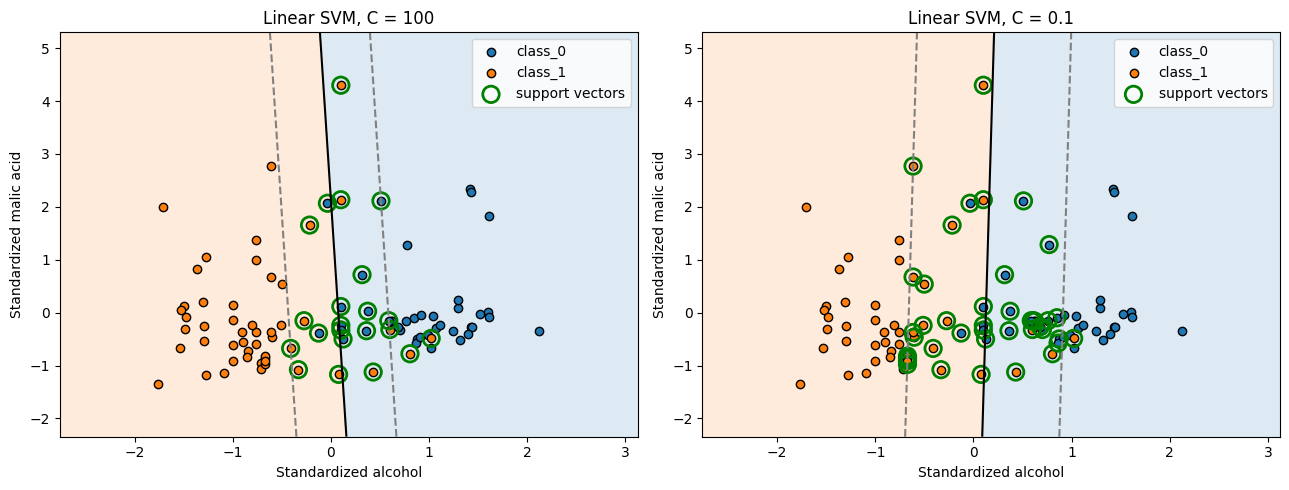

In [ ]:
def plot_svm_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, np.sign(Z), levels=[-2, 0, 2], alpha=0.15,
                colors=['tab:blue', 'tab:orange'])
    ax.contour(xx, yy, Z, levels=[-1, 0, 1],
               colors=['gray', 'k', 'gray'], linestyles=['--', '-', '--'])
    for cls, name, color in zip([0, 1], [class_names[0], class_names[1]],
                                 ['tab:blue', 'tab:orange']):
        pts = X[y == cls]
        ax.scatter(pts[:, 0], pts[:, 1], label=name, edgecolor='k', c=color)
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=140, facecolors='none', edgecolors='green',
               linewidths=2, label='support vectors')
    ax.set_xlabel('Standardized alcohol')
    ax.set_ylabel('Standardized malic acid')
    ax.set_title(title); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_svm_boundary(svm_large_C, X_train_s, y_train, axes[0], 'Linear SVM, C = 100')
plot_svm_boundary(svm_small_C, X_train_s, y_train, axes[1], 'Linear SVM, C = 0.1')
plt.tight_layout()
plt.show()